# Bank Churn Analysis: Python Charts
Companion notebook for the SQL project. The SQL file (`Bank_Churn_Analysis_Project.sql`) is the main analysis; this notebook adds three charts.

**Data:** `bank_churn_data.csv` (churned customers only, from the Kaggle "Credit Card Customers" dataset).
**Limitation:** with only churned customers, we can profile who leaves but cannot calculate churn *rate*.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("bank_churn_data.csv")
df.columns = df.columns.str.strip().str.lower()
print(df.shape)
df.head()

(1627, 13)


,card_category,churn,clientnum,education_level,gender,income,marital_status,balance,credit_limit,customer_age,dependent_count,months_on_book,utilization_ratio
0,Blue,Attrited Customer,708508758,Graduate,F,Less than $40K,Married,0,1438.3,62,0,49,0.000
1,Blue,Attrited Customer,708300483,Doctorate,F,Unknown,Married,605,7882.0,66,0,56,0.077
2,Blue,Attrited Customer,779471883,Graduate,F,Less than $40K,Married,808,1438.3,54,1,40,0.562
3,Blue,Attrited Customer,714374133,Graduate,M,$120K +,Married,0,15769.0,56,2,36,0.000
4,Silver,Attrited Customer,712030833,Graduate,M,$60K - $80K,Married,0,34516.0,48,2,35,0.000


In [2]:
AGE, INCOME, TENURE = "customer_age", "income", "months_on_book"
UTIL, LIMIT = "utilization_ratio", "credit_limit"
df[[AGE, INCOME, TENURE, UTIL, LIMIT]].isna().sum()

customer_age         0
income               0
months_on_book       0
utilization_ratio    0
credit_limit         0
dtype: int64

## Quick check: matches SQL query 1.1 to 1.5

In [3]:
summary = {
    "customers": len(df),
    "avg_age": round(df[AGE].mean()),
    "avg_credit_limit": round(df[LIMIT].mean(), 2),
    "avg_utilization": round(df[UTIL].mean(), 2),
}
expected = {"customers": 1627, "avg_age": 47, "avg_credit_limit": 8136.04, "avg_utilization": 0.16}
print("Matches the SQL results:", summary == expected)
summary

Matches the SQL results: True


{'customers': 1627, 'avg_age': 47, 'avg_credit_limit': np.float64(8136.04), 'avg_utilization': np.float64(0.16)}

## Chart 1: Churned customers by age group
Same age groups as the SQL file (section 11).

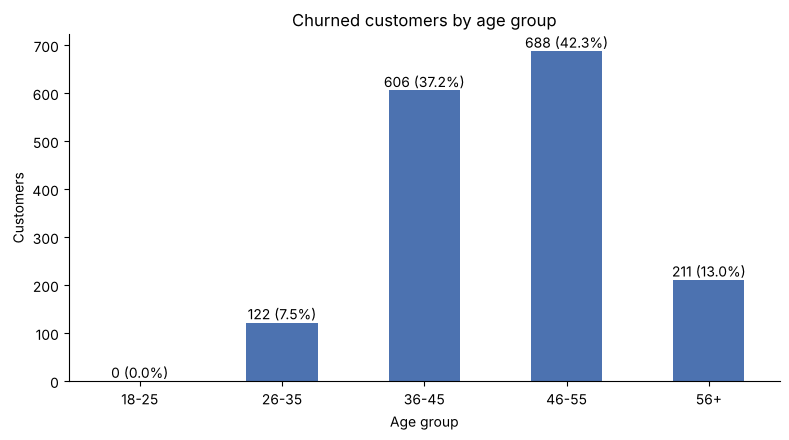

In [4]:
bins   = [17, 25, 35, 45, 55, 120]
labels = ["18-25", "26-35", "36-45", "46-55", "56+"]
df["age_group"] = pd.cut(df[AGE], bins=bins, labels=labels)

age_counts = df["age_group"].value_counts().reindex(labels)

ax = age_counts.plot(kind="bar", color="#4C72B0", rot=0)
ax.set_title("Churned customers by age group")
ax.set_xlabel("Age group")
ax.set_ylabel("Customers")
for i, v in enumerate(age_counts):
    ax.text(i, v, f"{v} ({v / len(df):.1%})", ha="center", va="bottom")
plt.tight_layout()
plt.savefig("chart_age_group.png", dpi=150)
plt.show()

## Chart 2: Churned customers by income group

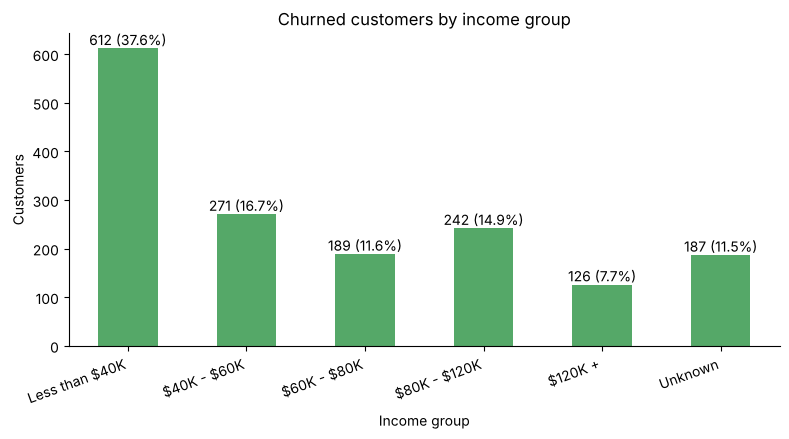

In [5]:
income_counts = df[INCOME].value_counts()

preferred = ["Less than $40K", "$40K - $60K", "$60K - $80K", "$80K - $120K", "$120K +", "Unknown"]
income_counts = income_counts.reindex([p for p in preferred if p in income_counts.index])

ax = income_counts.plot(kind="bar", color="#55A868", rot=20)
# "$" starts math text in matplotlib, so escape it to keep the dollar signs in the labels
ax.set_xticklabels([label.replace("$", r"\$") for label in income_counts.index], rotation=20, ha="right")
ax.set_title("Churned customers by income group")
ax.set_xlabel("Income group")
ax.set_ylabel("Customers")
for i, v in enumerate(income_counts):
    ax.text(i, v, f"{v} ({v / len(df):.1%})", ha="center", va="bottom")
plt.tight_layout()
plt.savefig("chart_income_group.png", dpi=150)
plt.show()

## Chart 3: How long customers stay before churning (tenure)

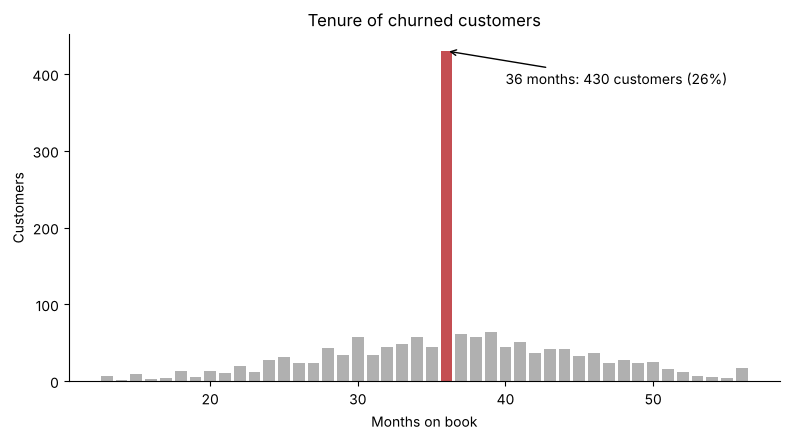

In [6]:
tenure_counts = df[TENURE].value_counts().sort_index()
peak = tenure_counts.idxmax()
colors = ["#C44E52" if m == peak else "#B0B0B0" for m in tenure_counts.index]

fig, ax = plt.subplots()
ax.bar(tenure_counts.index, tenure_counts.values, color=colors)
ax.set_title("Tenure of churned customers")
ax.set_xlabel("Months on book")
ax.set_ylabel("Customers")
ax.annotate(f"{peak} months: {tenure_counts[peak]} customers ({tenure_counts[peak] / len(df):.0%})",
            xy=(peak, tenure_counts[peak]), xytext=(peak + 4, tenure_counts[peak] * 0.9),
            arrowprops={"arrowstyle": "->"})
plt.tight_layout()
plt.savefig("chart_tenure.png", dpi=150)
plt.show()

## Key insights
- **Age:** the 46-55 group is the largest, with 688 churned customers (42.3%). Ages 36-55 together are about 80%, and no churned customer is under 26.
- **Income:** "Less than $40K" is the largest group (612 customers, 37.6%). This is a share of churners, not a churn rate, so it partly reflects how many customers the bank has in each group. The SQL file looks at balance, credit limit and tenure by income instead of counts, so this chart adds the count view.
- **Tenure:** churn spikes at exactly 36 months, with 430 customers (26.4%). This matches the SQL tenure result.

## Next step
Add the retained customers from the full Kaggle file so churn **rate** per segment can be calculated.